# Project Route Step Up Data Science and AI Challenge

## Can we trust the ride? When autonomous vehicles take the drive

Aim:
- Can you identify patterns that humans might miss?
- Which factors have the biggest impact on performance
- Can you predict when problems might occur?
- How could AI imporve future journeys?
- Based on the evidence, would you trust the ride?
- Bonus question: What ethical risks should we address?

What the notebook should include:

| **Output**       | **What it should answer**                                            |
| ---------------- | -------------------------------------------------------------------- |
| Chart 1          | Which operating condition shows the clearest performance difference? |
| Chart 2          | Which sensor, road or vehicle factor appears important?              |
| Model summary    | How well does the model detect problems on unseen test data?         |
| Confusion matrix | What are the consequences of false positives and false negatives?    |
| Ethics statement | What limitation or safeguard changes your trust decision?            |

Write recommendation (at the end):

| **Part**   | **What to include**                                             |
| ---------- | --------------------------------------------------------------- |
| Decision   | Would you trust the ride? State any conditions or boundaries.   |
| Evidence   | Refer to at least three calculated or visual findings.          |
| Model      | Report more than one metric and explain the errors.             |
| Limitation | State what the synthetic data and model cannot prove.           |
| Ethics     | Identify at least one affected group, risk and safeguard.       |
| Action     | Recommend one practical improvement and one measure to monitor. |

FINAL STRUCTURE:

Evidence + model evaluation + limitations + ethics + practical action = a defensible recommendation

# 1. Load files

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

journeys = pd.read_csv('Project-Route-Step-Up-Data-Science-CSV-Pack/autonomous_vehicle_journeys.csv')
journeys.head()

,journey_id,journey_date,time_of_day,city,road_segment_id,vehicle_profile_id,weather_code,road_type,distance_km,traffic_level,...,sensor_confidence_pct,sensor_alert_count,unexpected_obstacle,human_intervention,emergency_stop,safety_incident,journey_completed,passenger_rating_1to5,problem_occurred,risk_level
0,AVJ-00001,2026-04-12,Morning peak,Newcastle,SEG-018,VP-08,W07,B road,39.2,High,...,87.6,2,No,No,No,No,Yes,4,No,Low
1,AVJ-00002,2026-06-01,Night,Cardiff,SEG-009,VP-04,W01,Urban street,49.0,Moderate,...,93.5,1,No,No,No,No,Yes,5,No,Low
2,AVJ-00003,2026-02-18,Daytime,Cardiff,SEG-027,VP-08,W05,A road,11.3,Moderate,...,65.9,5,No,Yes,Yes,No,Yes,2,Yes,High
3,AVJ-00004,2026-06-23,Daytime,Cardiff,SEG-021,VP-08,W02,Motorway,15.3,Moderate,...,82.0,2,No,No,No,No,Yes,4,No,Low
4,AVJ-00005,2026-05-08,Daytime,Bristol,SEG-026,VP-04,W02,Motorway,25.1,Moderate,...,88.5,1,No,No,No,No,Yes,5,No,Low


In [10]:
journeys.shape

(2500, 25)

In [11]:
journeys.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   journey_id             2500 non-null   str    
 1   journey_date           2500 non-null   str    
 2   time_of_day            2500 non-null   str    
 3   city                   2500 non-null   str    
 4   road_segment_id        2500 non-null   str    
 5   vehicle_profile_id     2500 non-null   str    
 6   weather_code           2500 non-null   str    
 7   road_type              2500 non-null   str    
 8   distance_km            2500 non-null   float64
 9   traffic_level          2500 non-null   str    
 10  road_surface           2500 non-null   str    
 11  visibility_km          2500 non-null   float64
 12  planned_time_min       2500 non-null   int64  
 13  actual_time_min        2500 non-null   int64  
 14  delay_min              2500 non-null   int64  
 15  sensor_confiden

In [12]:
journeys.isna().sum() #no missing values

journey_id               0
journey_date             0
time_of_day              0
city                     0
road_segment_id          0
vehicle_profile_id       0
weather_code             0
road_type                0
distance_km              0
traffic_level            0
road_surface             0
visibility_km            0
planned_time_min         0
actual_time_min          0
delay_min                0
sensor_confidence_pct    0
sensor_alert_count       0
unexpected_obstacle      0
human_intervention       0
emergency_stop           0
safety_incident          0
journey_completed        0
passenger_rating_1to5    0
problem_occurred         0
risk_level               0
dtype: int64

In [13]:
journeys['problem_occurred'].value_counts()

problem_occurred
No     1999
Yes     501
Name: count, dtype: int64

1999 no problems occured, 501 problems occured

In [14]:
#change journey_date to datetime format
journeys['journey_date'] = pd.to_datetime(journeys['journey_date'])
assert journeys['journey_id'].is_unique

In [15]:
journeys.info() #journey_date now in datetime format

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   journey_id             2500 non-null   str           
 1   journey_date           2500 non-null   datetime64[us]
 2   time_of_day            2500 non-null   str           
 3   city                   2500 non-null   str           
 4   road_segment_id        2500 non-null   str           
 5   vehicle_profile_id     2500 non-null   str           
 6   weather_code           2500 non-null   str           
 7   road_type              2500 non-null   str           
 8   distance_km            2500 non-null   float64       
 9   traffic_level          2500 non-null   str           
 10  road_surface           2500 non-null   str           
 11  visibility_km          2500 non-null   float64       
 12  planned_time_min       2500 non-null   int64         
 13  actual_time_mi

# 2. Join Datasets

In [16]:
vehicles = pd.read_csv('Project-Route-Step-Up-Data-Science-CSV-Pack/vehicle_sensor_profiles.csv')
roads = pd.read_csv('Project-Route-Step-Up-Data-Science-CSV-Pack/road_environment_factors.csv')
weather = pd.read_csv('Project-Route-Step-Up-Data-Science-CSV-Pack/weather_risk_factors.csv')
events = pd.read_csv('Project-Route-Step-Up-Data-Science-CSV-Pack/intervention_events.csv')

In [17]:
events.head()

,event_id,journey_id,event_type,event_reason,severity,response_action,outcome
0,EVT-0001,AVJ-00003,Emergency stop,Emergency stop,Medium,Safe stop and system check,Journey completed
1,EVT-0002,AVJ-00007,Human intervention,Complex traffic,Low,Manual control requested,Journey completed
2,EVT-0003,AVJ-00008,Safety incident,Safety incident,High,Journey terminated,Journey not completed
3,EVT-0004,AVJ-00017,Human intervention,Unexpected obstacle,Low,Remote operator review,Journey completed
4,EVT-0005,AVJ-00019,Emergency stop,Emergency stop,Medium,Safe stop and system check,Journey not completed


In [18]:
#Join vehicle, road and weather information to the journeys

data = (journeys
        .merge(vehicles, on='vehicle_profile_id', how='left')
        .merge(roads, on='road_segment_id', how='left', suffixes=('', '_road'))
        .merge(weather, on='weather_code', how='left')
        )

print(data.shape)
print(data[['vehicle_model', 'junction_complexity', 'weather']].isna().sum())

(2500, 44)
vehicle_model          0
junction_complexity    0
weather                0
dtype: int64


# 3. Explore patterns

In [19]:
#create numeric target for calculations
#new column = 'problem_flag' based on problem_oocured (if yes = 1, no = 0 (int))
data['problem_flag'] = (data['problem_occurred'] == 'Yes').astype(int)

In [20]:
data.head()

,journey_id,journey_date,time_of_day,city,road_segment_id,vehicle_profile_id,weather_code,road_type,distance_km,traffic_level,...,speed_limit_mph,junction_complexity,road_markings,street_lighting,digital_infrastructure,weather,risk_multiplier,visibility_factor,sensor_confidence_adjustment,problem_flag
0,AVJ-00001,2026-04-12,Morning peak,Newcastle,SEG-018,VP-08,W07,B road,39.2,High,...,50,Low,Good,Standard,Standard,Low sun,1.30,0.70,-6,0
1,AVJ-00002,2026-06-01,Night,Cardiff,SEG-009,VP-04,W01,Urban street,49.0,Moderate,...,30,High,Good,Good,Standard,Clear,1.00,1.00,2,0
2,AVJ-00003,2026-02-18,Daytime,Cardiff,SEG-027,VP-08,W05,A road,11.3,Moderate,...,60,Low,Good,Standard,Standard,Snow,1.85,0.45,-15,1
3,AVJ-00004,2026-06-23,Daytime,Cardiff,SEG-021,VP-08,W02,Motorway,15.3,Moderate,...,70,Medium,Good,Limited,Standard,Light rain,1.15,0.82,-3,0
4,AVJ-00005,2026-05-08,Daytime,Bristol,SEG-026,VP-04,W02,Motorway,25.1,Moderate,...,70,Low,Good,Standard,Standard,Light rain,1.15,0.82,-3,0


In [21]:
#compare problem rates

#group by weather and problem flag (whether a problem occured (problem_occured = 1))
#get the mean of each weather groups and multiple by 100 to get a percentage
weather_rates = (data.groupby('weather')['problem_flag']
                 .mean().mul(100).sort_values())
print(weather_rates.round(1)) #round to whole number

weather
Clear          15.7
Strong wind    16.6
Light rain     17.9
Heat alert     22.0
Low sun        26.2
Heavy rain     27.6
Fog            32.5
Snow           47.7
Name: problem_flag, dtype: float64


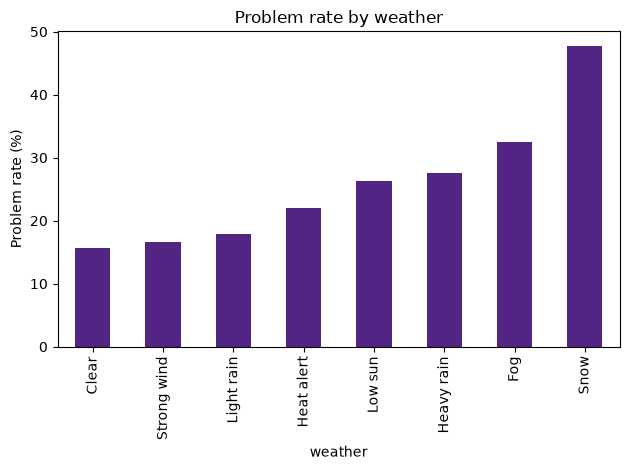

In [22]:
weather_rates.plot(kind='bar', color='#522584')
plt.ylabel('Problem rate (%)')
plt.title('Problem rate by weather')
plt.tight_layout()

Patterns and limits derived from this visual:

Problems occured more frequently when there are extreme weather. Clear weather have the least problem rate, while snow have the most problem rate. One possible explanation is that weather like heavy rain, fog and snow have low visibility, potentially making it difficult for sensors to detect objects and hazards.

However, it doesn't account to other variables like road types, distance, traffic level etc. which could be other causes of factors for why problems occur. Therefore, the relationship between weather and problems occured does not neccessarily imply that weather alone is responsible for the problems.

In [23]:
#calculate overall weather rate - to sort in ascending order later
weather_order = (data.groupby("weather")["problem_flag"]
                 .mean()
                 .sort_values()
                 .index)

In [24]:
#investigate road type and weather

weather_road_rate = data.groupby(["road_type", "weather"])["problem_flag"].mean().mul(100).unstack()

weather_road_rate = weather_road_rate[weather_order] #sort in ascending order

print(weather_road_rate.round(1))

weather       Clear  Strong wind  Light rain  Heat alert  Low sun  Heavy rain  \
road_type                                                                       
A road         13.8         20.0        11.2         6.2     17.2        25.7   
B road         16.4         12.5        18.2        33.3     28.6        27.9   
Motorway       13.2         12.8        14.4        36.4     24.0        26.1   
Rural road     17.0         15.6        23.6        14.3     40.7        17.9   
Urban street   18.3         27.3        23.0        23.1     20.0        40.0   

weather        Fog  Snow  
road_type                 
A road        37.5  42.1  
B road        27.9  45.0  
Motorway      39.3  61.1  
Rural road    35.7  52.9  
Urban street  24.1  33.3  


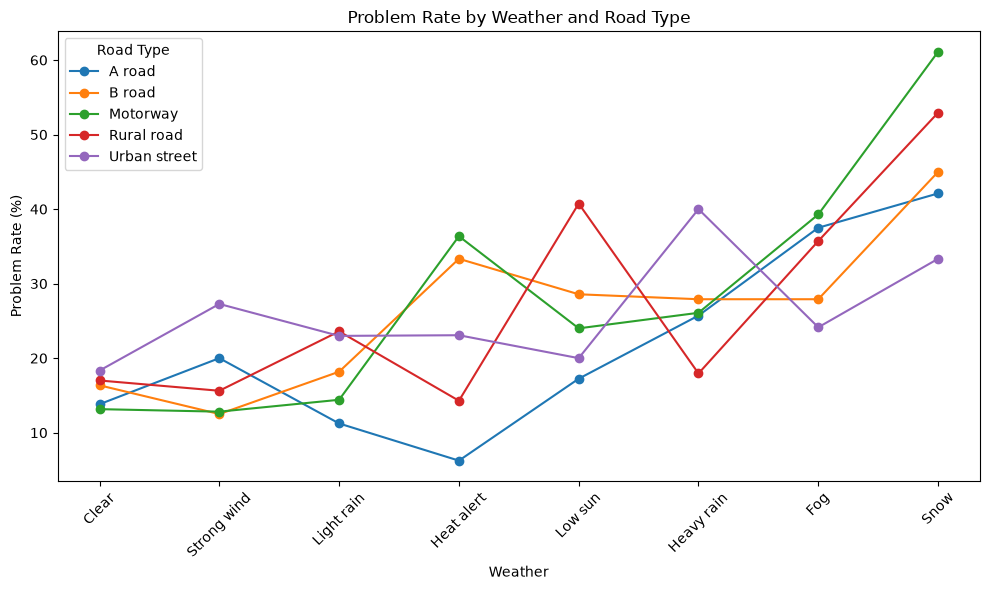

In [25]:
weather_road_rate.T.plot(marker='o', figsize=(10, 6))
plt.xlabel('Weather')
plt.ylabel('Problem Rate (%)')
plt.title('Problem Rate by Weather and Road Type')
plt.xticks(rotation=45)
plt.legend(title='Road Type')
plt.tight_layout()
plt.show()

The pattern remains relatively the same even when compared with road type and we got more insights into the relationship between weather and problem rates. However, the analysis cannot determine why certain road types and weather combinations have higher rates.

For example, rural road with low sun have the highest problem rate out of all the road type in the low sun category, which could potentially mean that rural roads could have very poor visibility especially with low sunlight. However, factors such as lighting, traffic level, road layout and time of day are not included in the analysis, hence these explanations cannot be confirmed from this visualization/analysis.



follow-up questions:
- does the pattern remain when you compare the same road type?
- are some categories based on relatively few journeys?
- could 2 factors be acting together?
- Is the pattern useful for action, or merely interesting?

# 4. Investigate factors humans might miss

In [26]:
# compare 2 conditions at once

pivot = pd.pivot_table(
    data, values='problem_flag',
    index='weather', columns='traffic_level',
    aggfunc='mean') * 100
print(pivot.round(1))

traffic_level  High   Low  Moderate
weather                            
Clear          22.4   8.6      14.6
Fog            34.5  21.9      35.7
Heat alert     26.1  30.8      13.0
Heavy rain     31.0  21.8      28.6
Light rain     18.8  12.4      20.5
Low sun        35.3  29.4      16.1
Snow           40.0  47.4      56.2
Strong wind    22.7  12.8      15.0


Text(0, 0.5, 'Sensor confidence (%)')

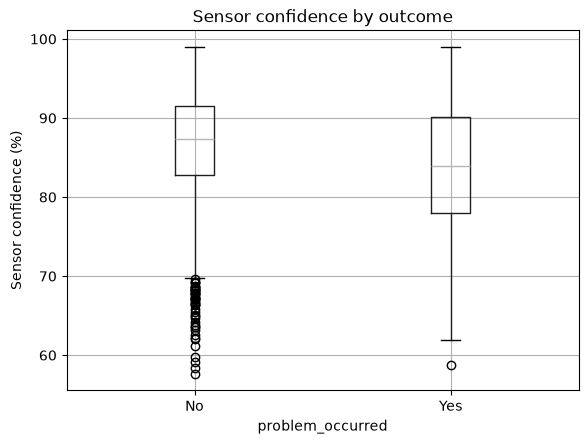

In [27]:
#inspect sensor confidence
data.boxplot(column='sensor_confidence_pct', by='problem_occurred')
plt.suptitle('')
plt.title('Sensor confidence by outcome')
plt.ylabel('Sensor confidence (%)')

Lower sensor confidence appears to be associated with a higher likelihood of a problem occuring.

Question:
- Do difficult conditions combine? (useful fields: weather, traffic_level, road_surface, visibility_km)
- Do sensors show warning signs? (useful fields: sensor_confidence_pct, sensor_alert_count)
- Do roads change the pattern (useful fields: road_type, junction_complexity, road_markings)
- Do vehicle profiles differ? (useful fields: sensor_suite, software_version, vehicle_age_months)
- Do obstacles matter? (useful fields: unexpected_obstacle)

**Example:** Journeys below 75% sensor confidence have a 41.6% problem rate; journeys at or above 90% have a 15.9% problem rate.



In [28]:
#Do difficult conditions combine?
 #(useful fields: weather, traffic_level, road_surface, visibility_km)

data["visibility_group"] = pd.cut(
    data["visibility_km"],
    bins=[0, 2, 5, 10, float("inf")],
    labels=["Very low", "Low", "Moderate", "High"]
)

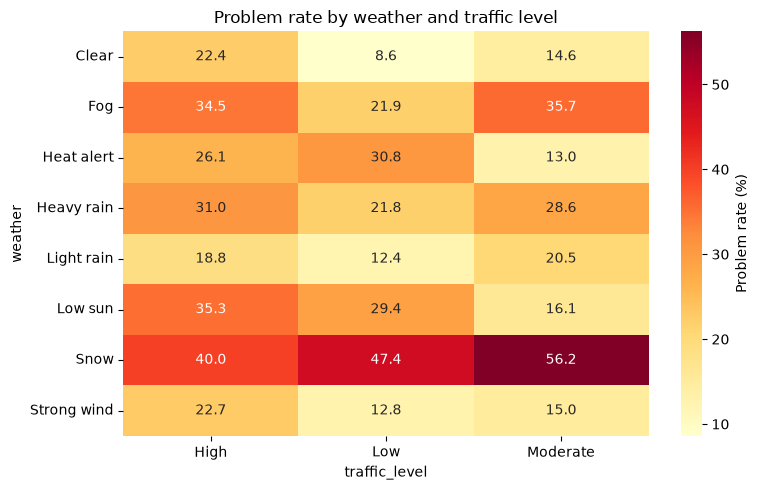

In [29]:
import seaborn as sns

main = (
    data.pivot_table(
        index="weather",
        columns="traffic_level",
        values="problem_flag",
        aggfunc="mean",
        observed=True
    ) * 100
)

counts = data.pivot_table(
    index="weather",
    columns="traffic_level",
    values="problem_flag",
    aggfunc="count",
    observed=True
)

plt.figure(figsize=(8, 5))
sns.heatmap(main, annot=True, fmt=".1f", cmap="YlOrRd",
            cbar_kws={"label": "Problem rate (%)"})
plt.title("Problem rate by weather and traffic level")
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Sensor Alert Count')

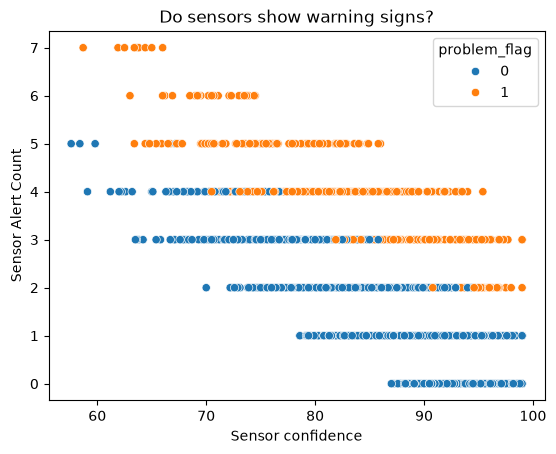

In [43]:
# Do sensors show warning signs?
# (useful fields: sensor_confidence_pct, sensor_alert_count)

sns.scatterplot(data = data, x="sensor_confidence_pct", y="sensor_alert_count", hue="problem_flag")
plt.title('Do sensors show warning signs?')
plt.xlabel('Sensor confidence')
plt.ylabel('Sensor Alert Count')

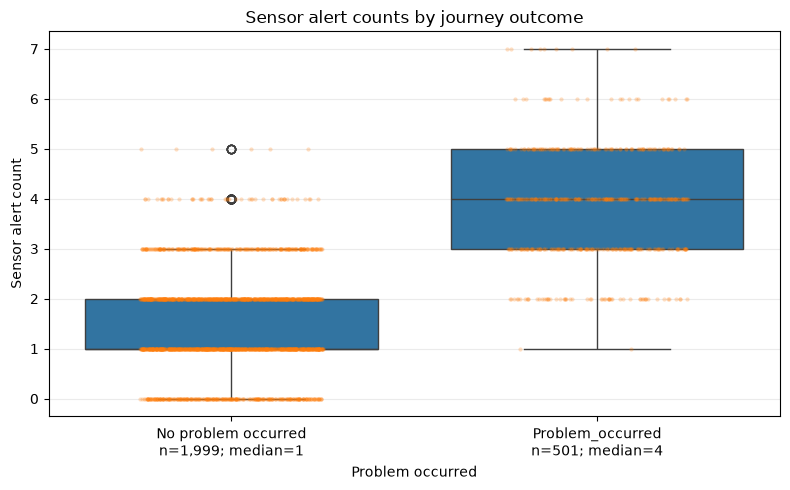

In [47]:
# Compare sensor alert counts for journeys with and without a problem
outcome_order = ["No", "Yes"]
alert_summary = data.groupby("problem_occurred")["sensor_alert_count"].agg(
    n="count", median="median"
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=data,
    x="problem_occurred",
    y="sensor_alert_count",
    order=outcome_order,
    ax=ax,
)
sns.stripplot(
    data=data,
    x="problem_occurred",
    y="sensor_alert_count",
    order=outcome_order,
    jitter=0.25,
    alpha=0.25,
    size=3,
    ax=ax,
)
ax.set_xticks([0, 1])
ax.set_xticklabels([
    f"{'Problem_occurred' if outcome == 'Yes' else 'No problem occurred'}\n"
    f"n={alert_summary.loc[outcome, 'n']:,}; "
    f"median={alert_summary.loc[outcome, 'median']:g}"
    for outcome in outcome_order
])
ax.set_title("Sensor alert counts by journey outcome")
ax.set_xlabel("Problem occurred")
ax.set_ylabel("Sensor alert count")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


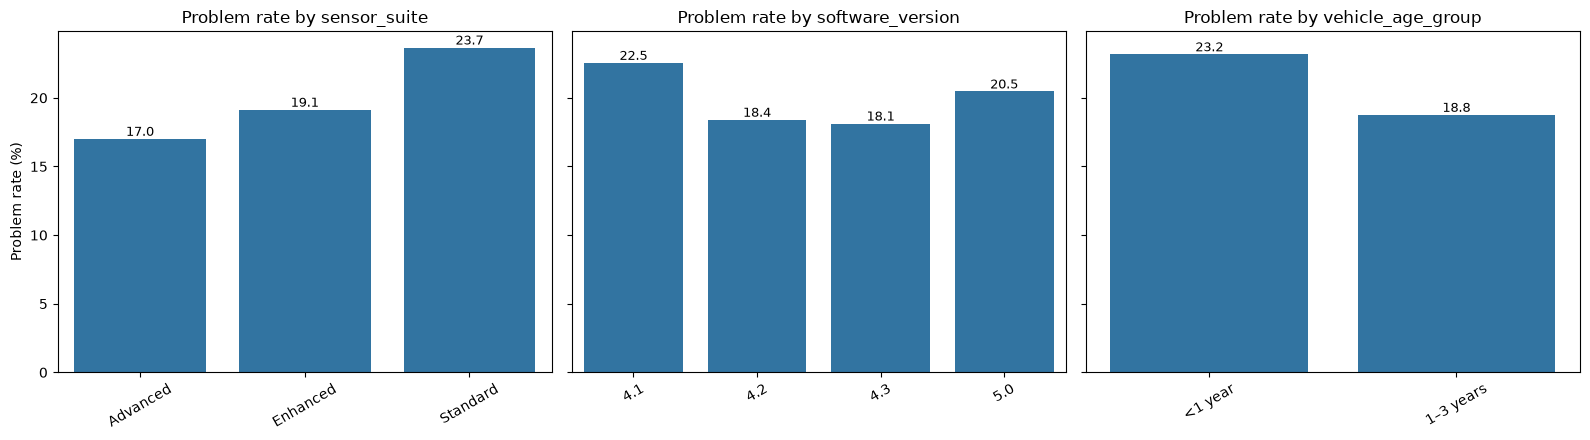

In [31]:
# Do vehicle profiles differ?
# (useful fields: sensor_suite, software_version, vehicle_age_months)

#group vehicle ages
data["vehicle_age_group"] = pd.cut(
    data["vehicle_age_months"],
    bins=[0, 12, 36, 60, float("inf")],
    labels=["<1 year", "1–3 years", "3–5 years", "5+ years"],
    include_lowest=True
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, col in zip(axes, ["sensor_suite", "software_version", "vehicle_age_group"]):
    rate = (data.groupby(col, observed=True)["problem_flag"].mean() * 100)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.set_title(f"Problem rate by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Problem rate (%)")
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(rate.values):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()


In [32]:
for col in ["sensor_suite", "software_version", "vehicle_age_group"]:
    print(
        data.groupby(col, observed=True)["problem_flag"]
            .agg(problem_rate=lambda s: s.mean() * 100, n="count")
            .round(1), "\n"
    )

              problem_rate     n
sensor_suite                    
Advanced              17.0   529
Enhanced              19.1  1223
Standard              23.7   748 

                  problem_rate    n
software_version                   
4.1                       22.5  785
4.2                       18.4  739
4.3                       18.1  502
5.0                       20.5  474 

                   problem_rate     n
vehicle_age_group                    
<1 year                    23.2   725
1–3 years                  18.8  1775 



In [33]:
#Do obstacles matter? (useful fields: unexpected_obstacle)

pivot = pd.pivot_table(
    data, values='problem_flag',
    index='weather', columns='unexpected_obstacle',
    aggfunc='mean') * 100
print(pivot.round(1))

unexpected_obstacle    No   Yes
weather                        
Clear                14.0  29.1
Fog                  28.6  60.0
Heat alert           24.5   0.0
Heavy rain           25.3  47.6
Light rain           17.6  20.4
Low sun              26.4  25.0
Snow                 50.0  30.0
Strong wind          15.4  25.0


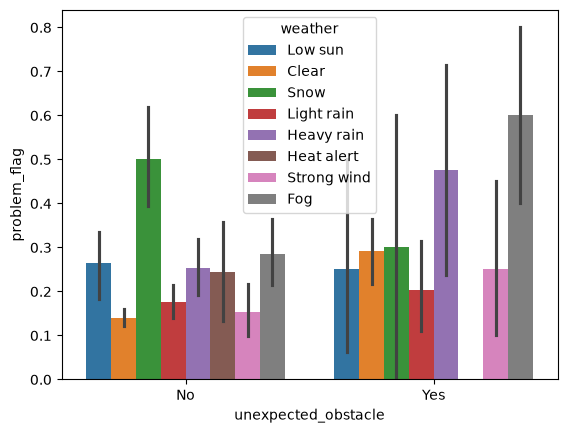

In [34]:
sns.barplot(x = 'unexpected_obstacle', y = 'problem_flag', hue='weather', data = data)
plt.show()

**Optional statistical extension:**
More confident students can test uncertainty using confidence intervals or a chi-square test. Report assumptions and effect size; do not treat a small p-value as proof of practical importance.

# 5. Prepare a fair prediction task

**Choose target:** use problem_occured (problem_flag as it's in int (must use in int)) as the classification target.

**The question is:**
Can information available before or during the journey help predict whether a performance problem occurs?

**Avoid target leakage:**
- risk_level: it was created from risk and outcome information closely related to the target
- human_intervention: it often happens because a problem has already developed
- emergency_stop: it is an outcome, not an easy predictor
- safety_incident: it is an outcome and would make the task unrealistically easy.
- journey_completed/passenger_rating_1to5: these are normally known after the journey


In [35]:
#feature set

features = [
    'time_of_day', 'road_type', 'traffic_level', 'road_surface',
    'visibility_km', 'distance_km', 'sensor_confidence_pct',
    'sensor_alert_count', 'unexpected_obstacle'
] #all features that we're gonna use to predict problem_occured
#(basically use everything except the features to be avoided above and problem_occured and problem_flag (as we're predicting those))
X = pd.get_dummies(data[features], drop_first=True)
y = data['problem_flag']

# 6. Build model

### 80/20 train-test split

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

### Train model

Train logistic regression

In [37]:
logistic_regression = LogisticRegression(max_iter=1000, class_weight='balanced')
logistic_regression.fit(X_train, y_train)
y_pred = logistic_regression.predict(X_test)

print(y_pred)

[1 0 0 0 1 1 0 0 1 1 0 0 0 0 0 1 0 0 0 1 0 0 1 0 0 1 0 0 0 1 0 1 0 1 0 0 1
 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 1 1 1 0 0 0 1 1 0 0 0 0 0 1 0 0 1 0 1 1
 1 1 0 1 0 1 1 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0
 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 1 1 0 0 1 1 0 1 1 0 1 1 0 0 0 0 1 1 1 0 1
 0 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 0 1
 0 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 1 1 1 0 0 1 0 1 1 0 0 0 1 0 1 0 0 0 0 1
 0 0 0 0 0 0 0 1 1 0 1 1 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 1
 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1
 1 1 0 0 1 1 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 1 0 1 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0
 0 0 0 1 1 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0
 0 1 0 0 0 0 0 0 1 0 0 0 

Why logistic regression?

Logistic regression is a useful transparent baseline. It predicts a probability and lets you inspect how features affect the prediction.

Train decision-tree (for comparison)

In [38]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')

tree.fit(X_train, y_train)

UnicodeDecodeError: 'charmap' codec can't decode byte 0x9c in position 2951: character maps to <undefined>

UnicodeDecodeError: 'charmap' codec can't decode byte 0x9c in position 2951: character maps to <undefined>

DecisionTreeClassifier(class_weight='balanced', max_depth=4, random_state=42)

# 7. Evaluate Model

              precision    recall  f1-score   support

           0       0.99      0.94      0.96       400
           1       0.79      0.98      0.88       100

    accuracy                           0.94       500
   macro avg       0.89      0.96      0.92       500
weighted avg       0.95      0.94      0.95       500

Accuracy: 0.944
Precision: 0.7903225806451613
Recall 0.98
F1: 0.875


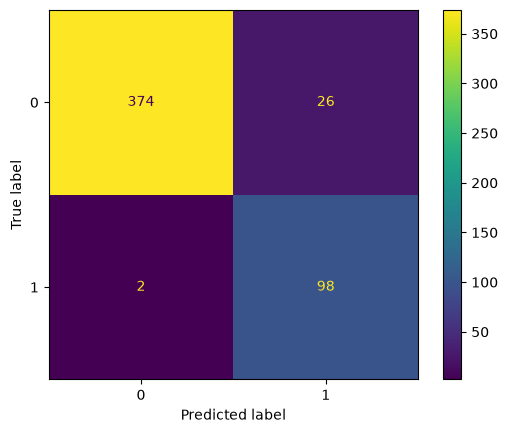

In [39]:
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, ConfusionMatrixDisplay,
                             classification_report)

print(classification_report(y_test, y_pred))
print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall', recall_score(y_test, y_pred))
print('F1:', f1_score(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

**Metrics:**

- ***Accuracy*** - How many predictors were correct overall?
- ***Precision*** - When the model predicts a problem, how often is it right?
- ***Recall*** - How many real problems did the model detect
- ***F1 score*** - How well does it balance precision and recall?
- ***Confusion matrix*** - How many correct and incorrect decisions of each type?

SAFETY CONTEXT: A false negative is a missed problem. In a safety-related setting, *recall* matters - but excessive false alarms can also reduce trust or cause unneccessary intervention

# 8.Explain what the model learned

In [40]:
#Inspect logistic-regression coefficients
importance = pd.Series(logistic_regression.coef_[0], index=X.columns)
importance = importance.reindex(importance.abs().sort_values(ascending=False).index)
print(importance.head(12))

sensor_alert_count           5.667646
road_surface_Snow-covered    1.326815
traffic_level_Low           -0.965238
sensor_confidence_pct        0.576749
road_type_Motorway          -0.574313
road_type_B road            -0.297074
road_type_Rural road        -0.294068
road_surface_Wet            -0.286196
time_of_day_Morning peak     0.283553
time_of_day_Late night      -0.269153
traffic_level_Moderate      -0.200940
time_of_day_Evening peak     0.177830
dtype: float64


Interpretation:
- A positive coefficient increases the modelled likelihood of a problem; a negative coefficient decreases it.
- Category coefficients are relative to the category removed by drop_first=True
- The features use different units, so raw coefficient sizes cannot reliably rank their importance. A large coefficient also does not prove causation
- Correlated features can make individual coefficients unstable
- Check whether the result makes transport and safety sense.

Turn findings into possible improvements:

| **Finding**                             | **Possible AI or operational response**                                          |
| ------------ | --------------------------|
| Low sensor confidence predicts problems | Combine sensors, improve calibration or request earlier human review.            |
| Weather raises risk                     | Use weather-aware thresholds and train on more adverse-condition data.           |
| Unexpected obstacles matter             | Improve object detection and test rare pedestrian, cyclist and debris scenarios. |
| Certain road conditions perform worse   | Prioritise targeted testing and infrastructure monitoring.                       |
| Model uncertainty is high               | Slow down, seek human oversight or choose a safer operating mode.                |

EXPLAINABILITY: A recommendation should be understandable to passengers, engineers, operators and regulators - not only to the person who built the model.

